In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samuelcortinhas/muffin-vs-chihuahua-image-classification")

print("Path to dataset files:", path)

c:\Users\user\OneDrive - Braude College of Engineering - EDU\מסמכים\GitHub\AI-ethics\.venv-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\user\.cache\kagglehub\datasets\samuelcortinhas\muffin-vs-chihuahua-image-classification\versions\2


In [6]:
import torch
import os
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

# Dataset
train_dataset = ImageFolder(
    os.path.join(path, "train"),
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(5):
    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch:", epoch+1, "Loss:", loss.item())


Epoch: 1 Loss: 0.3915293216705322
Epoch: 2 Loss: 0.3127012252807617
Epoch: 3 Loss: 0.42041319608688354
Epoch: 4 Loss: 0.1583009660243988
Epoch: 5 Loss: 0.23810502886772156


In [7]:
import pandas as pd
from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

test_dataset = ImageFolder(
    os.path.join(path, "test"),
    transform=transform
)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model.eval()

results = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        for i in range(len(preds)):
            img_path = test_dataset.samples[len(results)][0]
            img_name = img_path.split("/")[-1]

            label = train_dataset.classes[preds[i].item()]

            results.append({
                "ID": img_name,
                "Predict": label
            })

submission = pd.DataFrame(results)
submission.to_csv("submission.csv", index=False)

print("submission.csv created!")

submission.csv created!


In [8]:
import torch
print(torch.cuda.is_available())

False


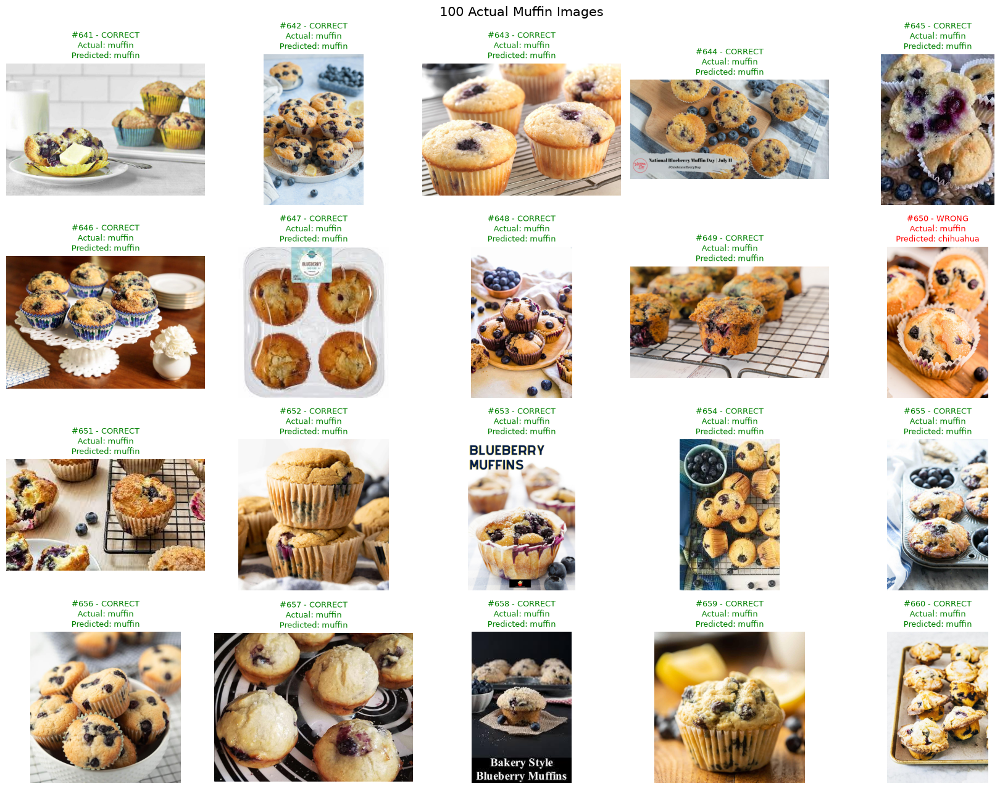

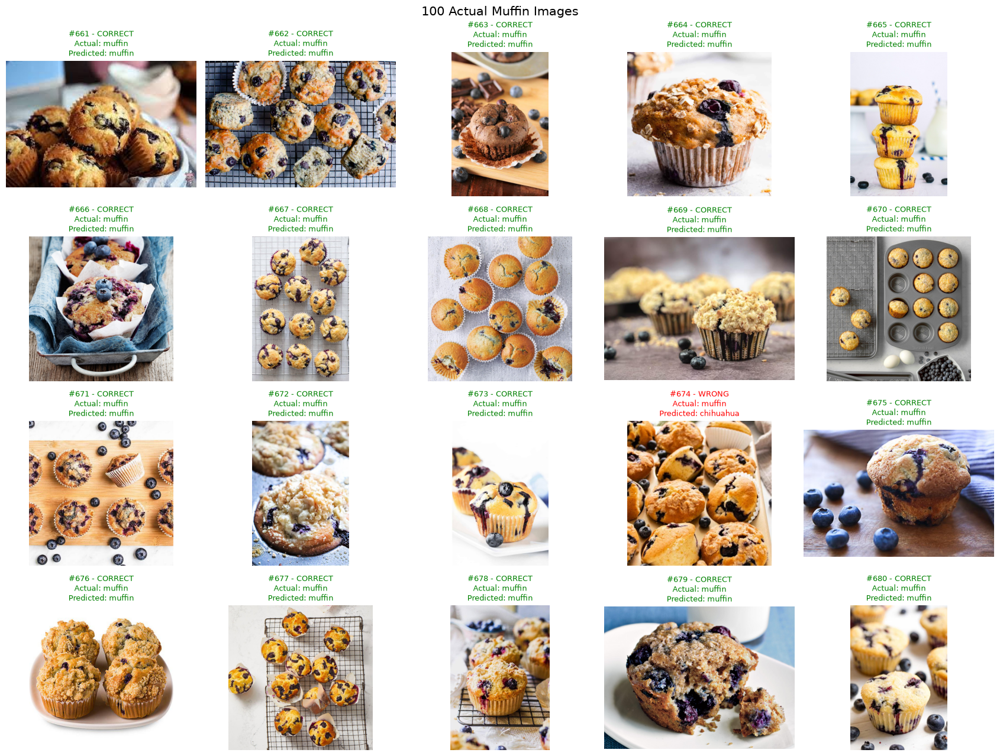

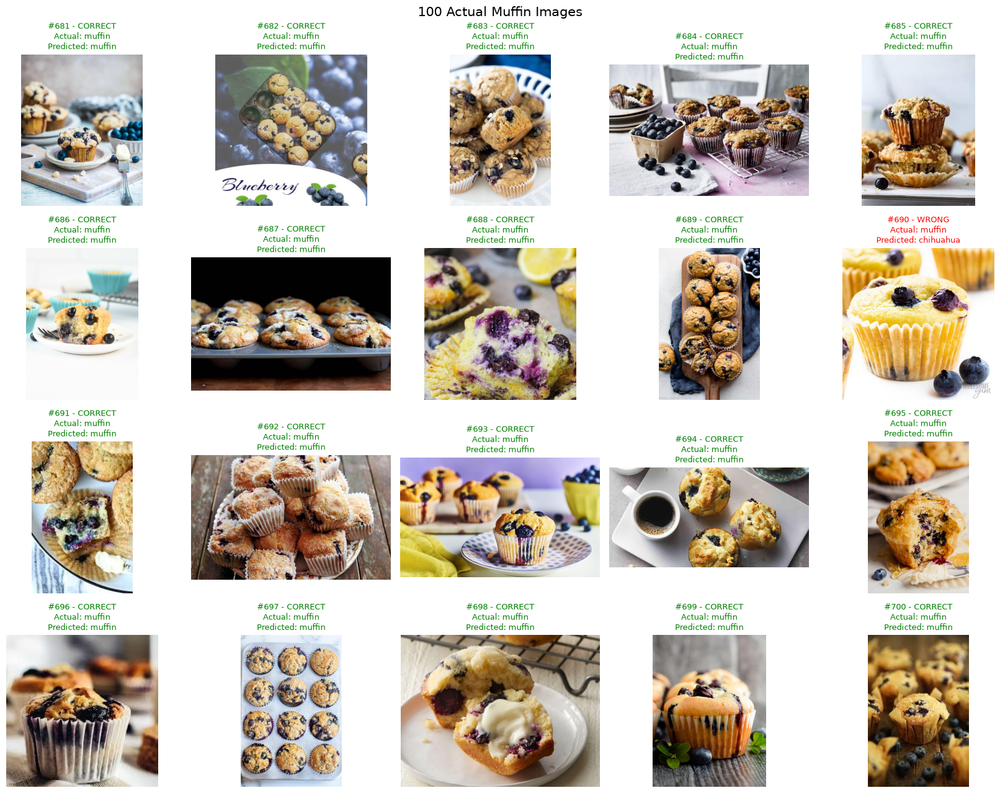

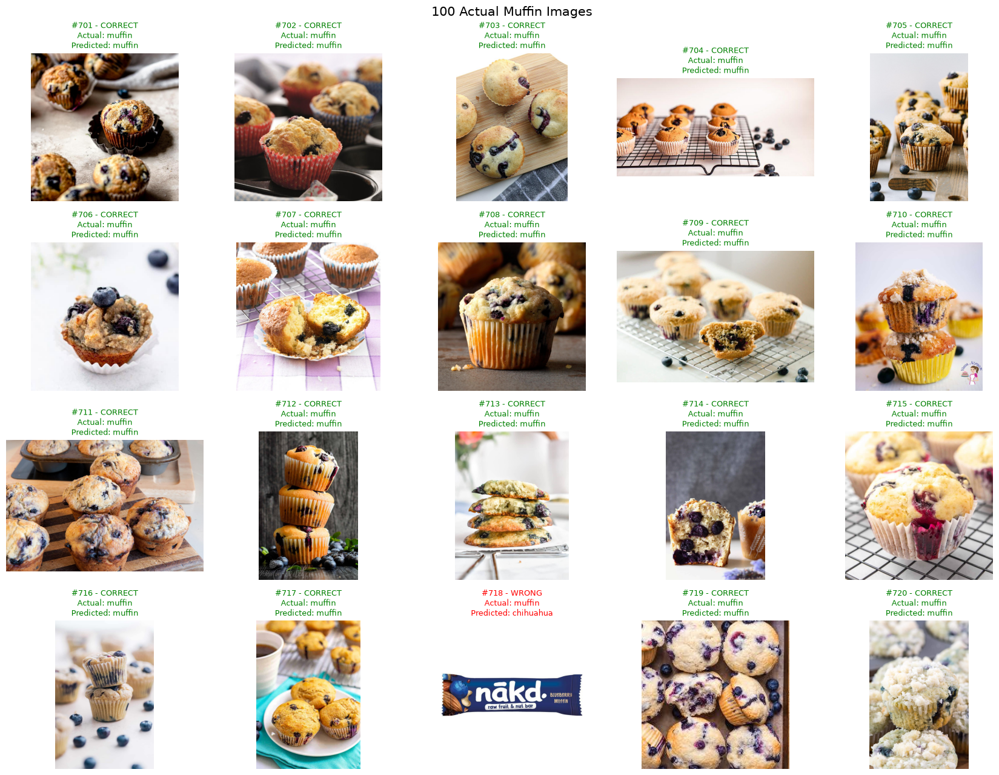

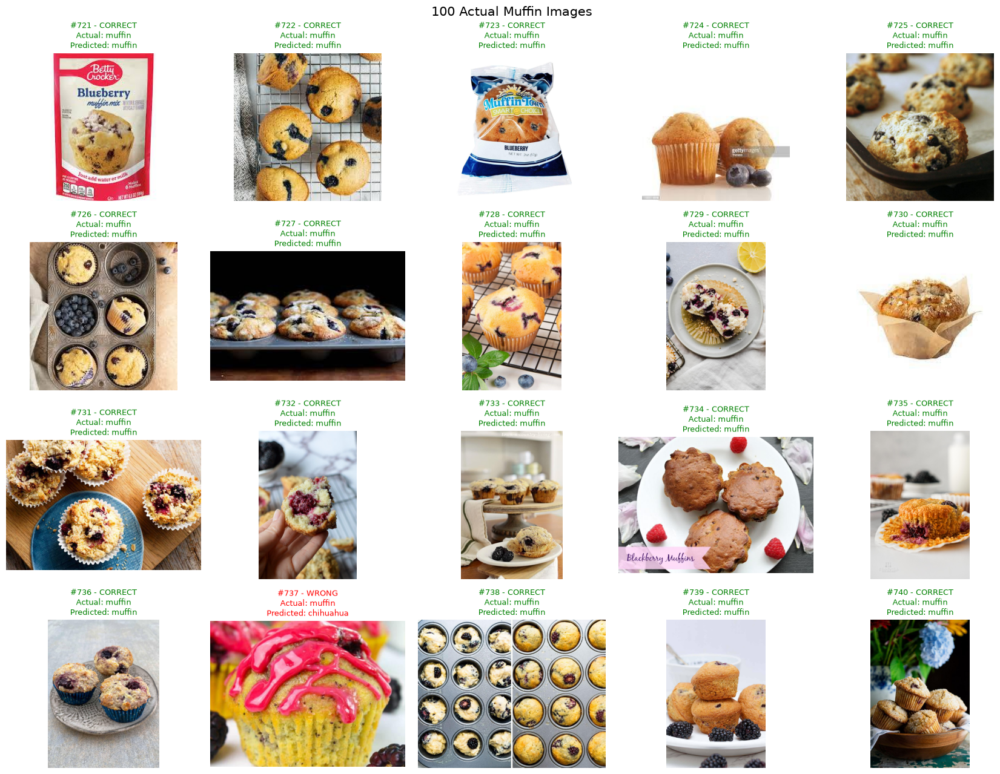

100 Actual Muffin Images: 95/100 correct (95.0%)


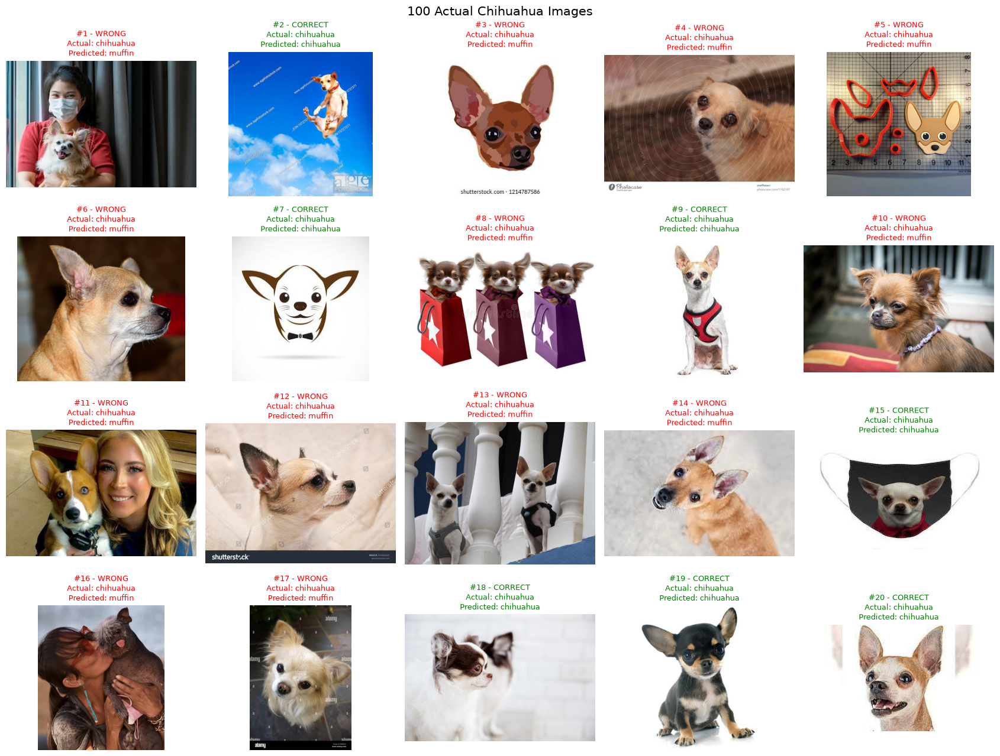

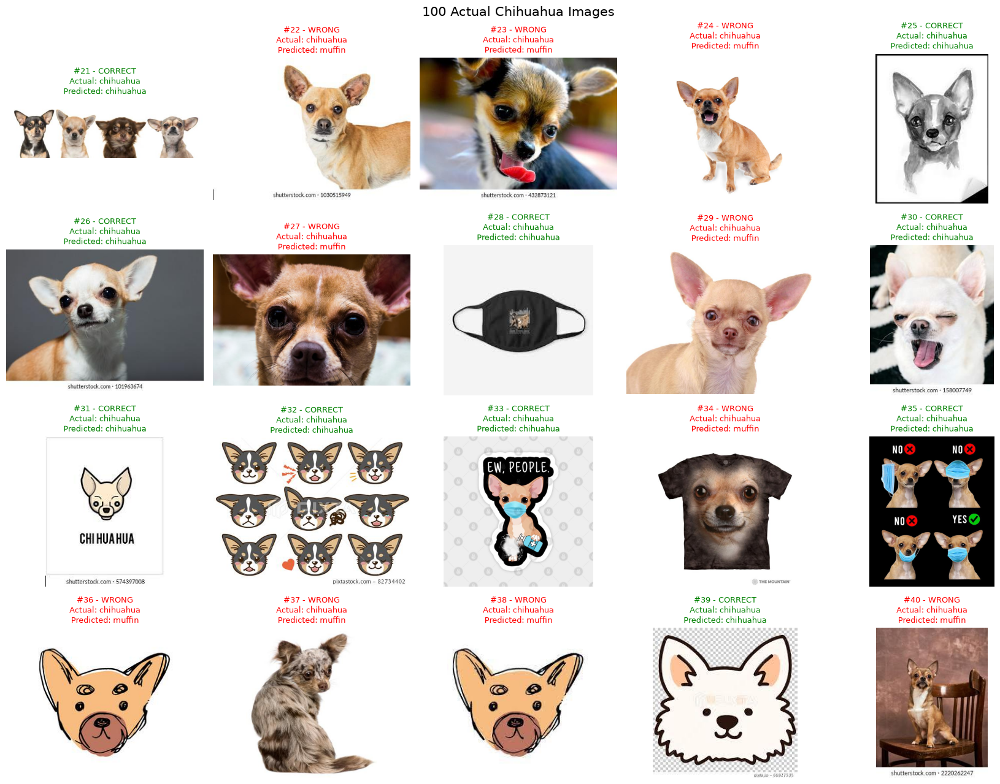

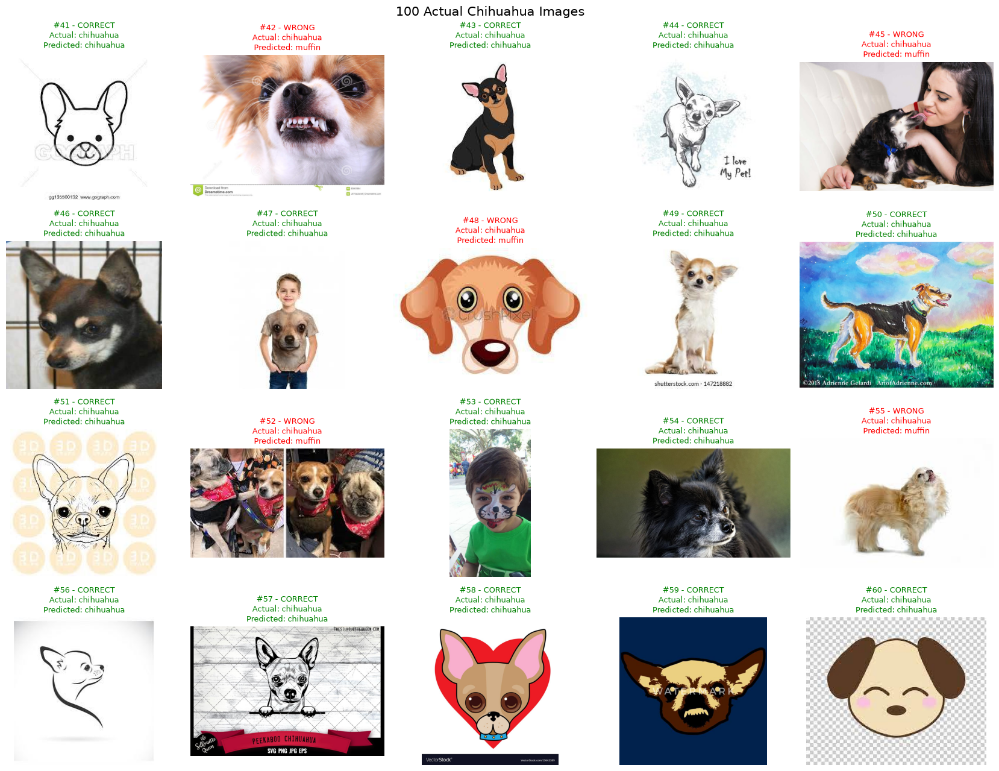

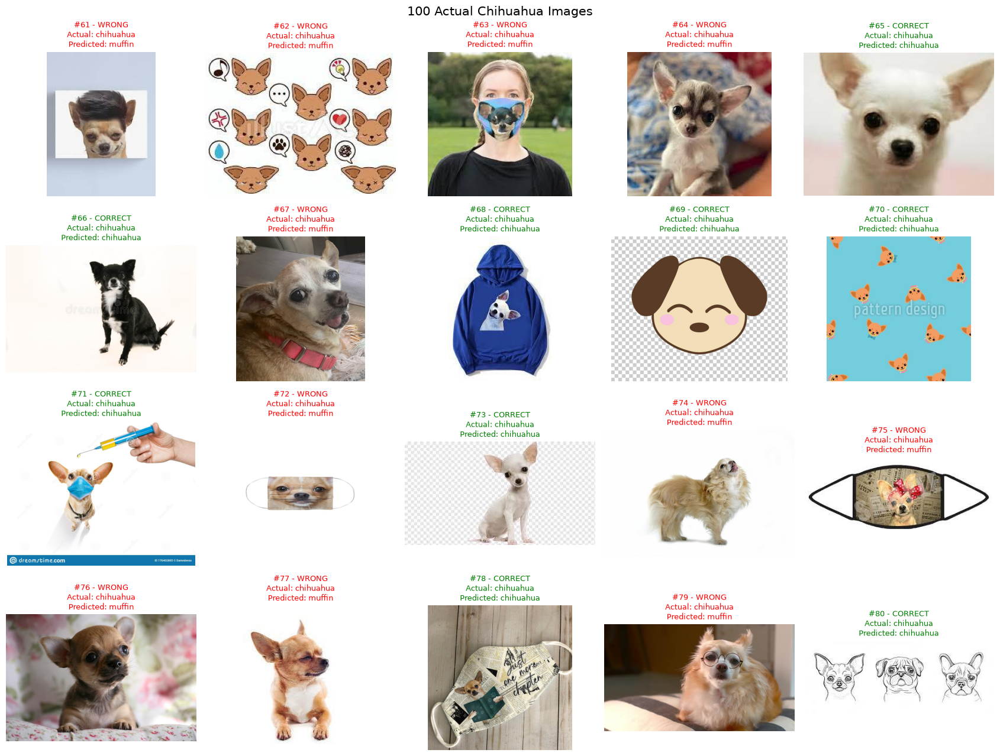

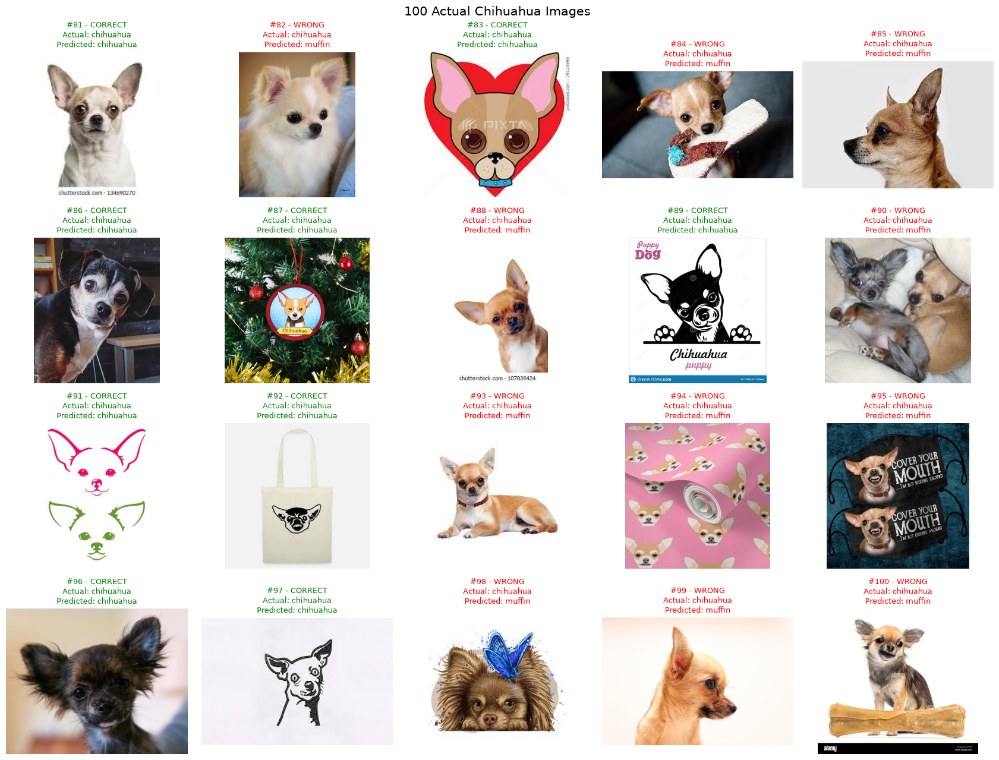

100 Actual Chihuahua Images: 50/100 correct (50.0%)


In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.datasets import ImageFolder
import kagglehub

# Dataset and CSV
data_path = kagglehub.dataset_download(
    "samuelcortinhas/muffin-vs-chihuahua-image-classification"
)
dataset = ImageFolder(os.path.join(data_path, "test"))
df = pd.read_csv("submission.csv")

for i, csv_id in enumerate(df["ID"]):
    image_path, _ = dataset.samples[i]
    csv_name = str(csv_id).replace("\\", "/").split("/")[-1]
    if csv_name != os.path.basename(image_path):
        raise ValueError(f"Image mismatch at row {i + 1}")

def show_gallery(indices, title):
    correct = 0

    for start in range(0, len(indices), 20):
        batch = indices[start:start + 20]
        fig, axes = plt.subplots(4, 5, figsize=(17, 13))

        for ax in axes.flat:
            ax.axis("off")

        for ax, i in zip(axes.flat, batch):
            image_path, class_id = dataset.samples[i]
            actual = dataset.classes[class_id]
            predicted = str(df.iloc[i]["Predict"]).strip()

            is_correct = actual.lower() == predicted.lower()
            correct += int(is_correct)

            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(
                f"#{i+1} - {'CORRECT' if is_correct else 'WRONG'}\n"
                f"Actual: {actual}\n"
                f"Predicted: {predicted}",
                color="green" if is_correct else "red",
                fontsize=9
            )

        fig.suptitle(title, fontsize=15)
        plt.tight_layout()
        plt.show()

    if indices:
        print(f"{title}: {correct}/{len(indices)} correct ({correct / len(indices):.1%})")
    else:
        print(f"No images found for: {title}")

muffin_100 = [
    i for i, (_, class_id) in enumerate(dataset.samples[:len(df)])
    if dataset.classes[class_id].lower() == "muffin"
][:100]

chihuahua_100 = [
    i for i, (_, class_id) in enumerate(dataset.samples[:len(df)])
    if dataset.classes[class_id].lower() == "chihuahua"
][:100]

show_gallery(muffin_100, "100 Actual Muffin Images")
show_gallery(chihuahua_100, "100 Actual Chihuahua Images")

Total test images: 1184
Correct predictions: 831
Incorrect predictions: 353
Overall Accuracy: 70.19%

Precision, Recall and F1-score by class:
       Class  Precision  Recall  F1-score  Support
   chihuahua     0.9208  0.4906    0.6402      640
      muffin     0.6133  0.9504    0.7455      544
   macro avg     0.7671  0.7205    0.6928     1184
weighted avg     0.7795  0.7019    0.6886     1184

Confusion matrix (rows = actual; columns = predicted):
Predicted  chihuahua  muffin
Actual                      
chihuahua        314     326
muffin            27     517


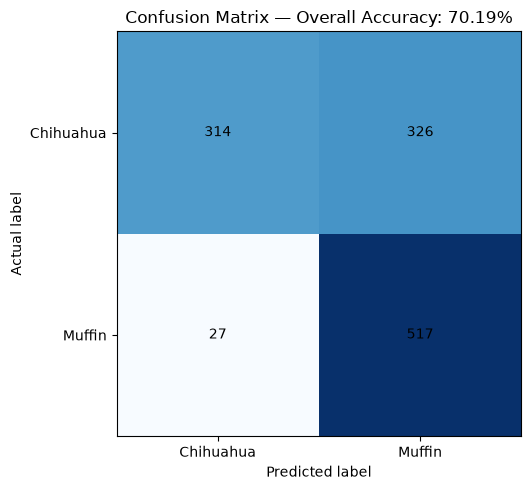


Saved: evaluation_all_predictions.csv, evaluation_class_metrics.csv, evaluation_summary.csv


In [ ]:
# Overall evaluation on ALL test images (not only the 200 gallery examples)
# Uses submission.csv and the actual class labels from the test folders.
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from torchvision.datasets import ImageFolder

# Load the same test dataset and prediction file used by the notebook.
data_path = kagglehub.dataset_download(
    "samuelcortinhas/muffin-vs-chihuahua-image-classification"
)
full_test_dataset = ImageFolder(os.path.join(data_path, "test"))
eval_df = pd.read_csv("submission.csv")

if not {"ID", "Predict"}.issubset(eval_df.columns):
    raise ValueError("submission.csv must contain ID and Predict columns")
if len(eval_df) != len(full_test_dataset.samples):
    raise ValueError(
        f"Overall evaluation requires all {len(full_test_dataset.samples)} test images, "
        f"but submission.csv has {len(eval_df)} rows"
    )

# Check that each prediction belongs to the corresponding test image.
actual_labels = []
for i, (image_path, class_index) in enumerate(full_test_dataset.samples):
    csv_name = str(eval_df.iloc[i]["ID"]).replace("\\", "/").split("/")[-1]
    if csv_name != os.path.basename(image_path):
        raise ValueError(f"CSV/image mismatch at row {i + 1}: {csv_name}")
    actual_labels.append(full_test_dataset.classes[class_index].casefold())

eval_df["Actual"] = actual_labels
eval_df["Predicted"] = eval_df["Predict"].astype(str).str.strip().str.casefold()
classes = [name.casefold() for name in full_test_dataset.classes]
invalid = sorted(set(eval_df["Predicted"]) - set(classes))
if invalid:
    raise ValueError(f"Unknown predicted class labels: {invalid}")

eval_df["Correct"] = eval_df["Actual"] == eval_df["Predicted"]
total = len(eval_df)
correct = int(eval_df["Correct"].sum())
accuracy = correct / total

# Rows = actual labels; columns = predicted labels.
confusion = pd.crosstab(
    eval_df["Actual"], eval_df["Predicted"],
    rownames=["Actual"], colnames=["Predicted"]
).reindex(index=classes, columns=classes, fill_value=0)

# Standard class-wise classification metrics.
rows = []
for cls in classes:
    tp = int(confusion.loc[cls, cls])
    support = int(confusion.loc[cls].sum())
    fp = int(confusion[cls].sum()) - tp
    fn = support - tp
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({
        "Class": cls, "Precision": precision, "Recall": recall,
        "F1-score": f1, "Support": support,
    })

metrics_df = pd.DataFrame(rows)
macro = metrics_df[["Precision", "Recall", "F1-score"]].mean()
weighted = (
    metrics_df[["Precision", "Recall", "F1-score"]]
    .multiply(metrics_df["Support"], axis=0).sum() / total
)
metrics_df = pd.concat([
    metrics_df,
    pd.DataFrame([
        {"Class": "macro avg", **macro.to_dict(), "Support": total},
        {"Class": "weighted avg", **weighted.to_dict(), "Support": total},
    ])
], ignore_index=True)

print(f"Total test images: {total}")
print(f"Correct predictions: {correct}")
print(f"Incorrect predictions: {total - correct}")
print(f"Overall Accuracy: {accuracy:.2%}")
print("\nPrecision, Recall and F1-score by class:")
print(metrics_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nConfusion matrix (rows = actual; columns = predicted):")
print(confusion.to_string())

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(confusion.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(classes)), [s.title() for s in classes])
ax.set_yticks(range(len(classes)), [s.title() for s in classes])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title(f"Confusion Matrix — Overall Accuracy: {accuracy:.2%}")
for r in range(len(classes)):
    for c in range(len(classes)):
        ax.text(c, r, str(int(confusion.iloc[r, c])), ha="center", va="center")
plt.tight_layout()
plt.show()

# Report-ready exports: every prediction, class metrics, and overall summary.
eval_df[["ID", "Actual", "Predicted", "Correct"]].to_csv(
    "evaluation_all_predictions.csv", index=False
)
metrics_df.to_csv("evaluation_class_metrics.csv", index=False)
pd.DataFrame([{
    "Test images": total,
    "Correct": correct,
    "Incorrect": total - correct,
    "Accuracy": accuracy,
    "Macro F1": float(macro["F1-score"]),
    "Weighted F1": float(weighted["F1-score"]),
}]).to_csv("evaluation_summary.csv", index=False)
print("\nSaved: evaluation_all_predictions.csv, evaluation_class_metrics.csv, evaluation_summary.csv")
